# Thin-film coatings with the transfer-matrix method

This notebook uses the `thinfilm` package to compare three classic designs:

1. an uncoated glass surface,
2. a single-layer MgF$_2$ anti-reflection (AR) coating,
3. a quarter-wave TiO$_2$/SiO$_2$ Bragg mirror.

All indices are taken as constant except the BK7 substrate, which uses its Sellmeier dispersion.

In [1]:
import sys, math
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
import thinfilm as tf

INF = math.inf
wl = np.linspace(0.40, 0.80, 401)  # micrometres
lam0 = 0.55                         # design wavelength

## 1. Bare glass vs. MgF$_2$ AR coating

The ideal single-layer AR index for BK7 is $\sqrt{1.52} \approx 1.23$. No durable material has an index that low, so MgF$_2$ ($n \approx 1.38$) is the usual compromise.

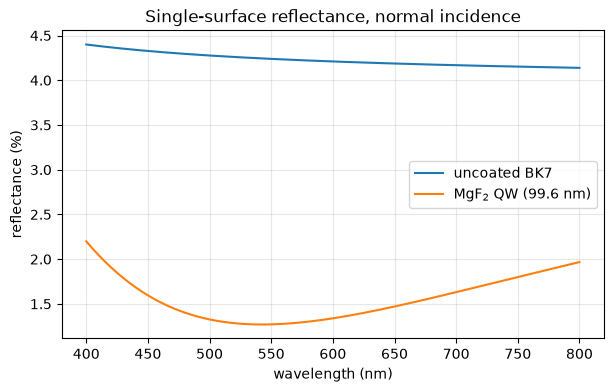

R at 550 nm: bare = 4.24 %, MgF2 = 1.27 %


In [2]:
n_mgf2 = 1.38
d_mgf2 = tf.quarter_wave_thickness(n_mgf2, lam0)

R_bare, _ = tf.spectrum("s", lambda l: [1.0, tf.bk7(l)], [INF, INF], 0.0, wl)
R_ar, _ = tf.spectrum("s", lambda l: [1.0, n_mgf2, tf.bk7(l)], [INF, d_mgf2, INF], 0.0, wl)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(wl * 1e3, R_bare * 100, label="uncoated BK7")
ax.plot(wl * 1e3, R_ar * 100, label=f"MgF$_2$ QW ({d_mgf2*1e3:.1f} nm)")
ax.set(xlabel="wavelength (nm)", ylabel="reflectance (%)", title="Single-surface reflectance, normal incidence")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

print(f"R at {lam0*1e3:.0f} nm: bare = {R_bare[np.argmin(abs(wl-lam0))]*100:.2f} %, "
      f"MgF2 = {R_ar[np.argmin(abs(wl-lam0))]*100:.2f} %")

## 2. Quarter-wave Bragg mirror

Peak reflectance grows rapidly with the number of high/low pairs. The closed-form value from the admittance recursion is printed alongside the TMM result as a check.

2 pairs: TMM R = 0.674809, closed form = 0.674809
4 pairs: TMM R = 0.943258, closed form = 0.943258
8 pairs: TMM R = 0.998704, closed form = 0.998704


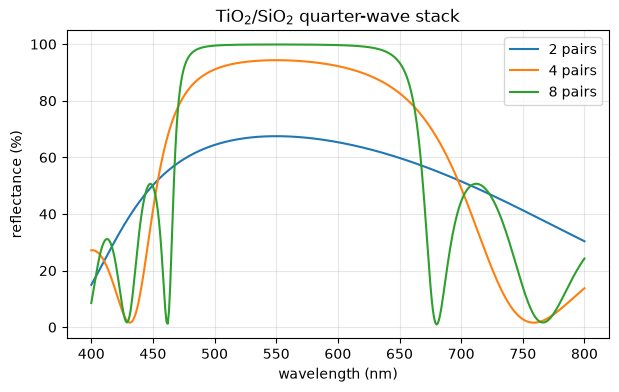

In [3]:
nH, nL = 2.35, 1.46
fig, ax = plt.subplots(figsize=(7, 4))
for pairs in (2, 4, 8):
    n_list, d_list = tf.bragg_mirror(1.0, nH, nL, 1.52, pairs, lam0)
    R, _ = tf.spectrum("s", lambda l, nl=n_list: nl, d_list, 0.0, wl)
    ax.plot(wl * 1e3, R * 100, label=f"{pairs} pairs")
    peak = tf.coh_tmm("s", n_list, d_list, 0.0, lam0).R
    print(f"{pairs} pairs: TMM R = {peak:.6f}, closed form = "
          f"{tf.quarter_wave_stack_reflectance(1.0, nH, nL, 1.52, pairs):.6f}")
ax.set(xlabel="wavelength (nm)", ylabel="reflectance (%)", title="TiO$_2$/SiO$_2$ quarter-wave stack")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

The stop-band width depends only on the index contrast:
$\Delta\lambda / \lambda_0 = \frac{4}{\pi}\arcsin\left(\frac{n_H - n_L}{n_H + n_L}\right)$.

In [4]:
frac = 4 / math.pi * math.asin((nH - nL) / (nH + nL))
print(f"predicted stop-band width: {frac * lam0 * 1e3:.0f} nm")

predicted stop-band width: 165 nm


## 3. Angle dependence and Brewster's angle

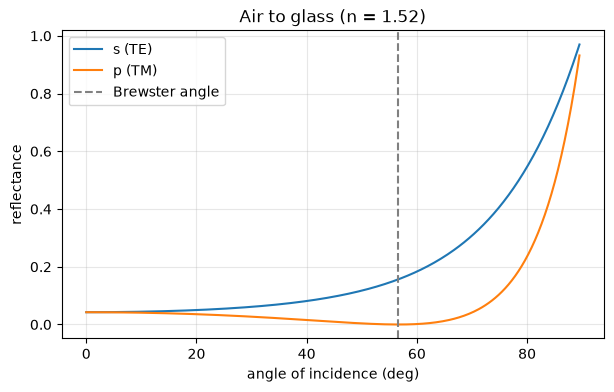

In [5]:
theta = np.radians(np.linspace(0, 89.5, 300))
Rs = [tf.coh_tmm("s", [1.0, 1.52], [INF, INF], t, lam0).R for t in theta]
Rp = [tf.coh_tmm("p", [1.0, 1.52], [INF, INF], t, lam0).R for t in theta]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.degrees(theta), Rs, label="s (TE)")
ax.plot(np.degrees(theta), Rp, label="p (TM)")
ax.axvline(math.degrees(math.atan(1.52)), ls="--", c="gray", label="Brewster angle")
ax.set(xlabel="angle of incidence (deg)", ylabel="reflectance", title="Air to glass (n = 1.52)")
ax.legend(); ax.grid(alpha=0.3)
plt.show()